# Previsão do consumo elétrico de edifícios universitários

Edifícios: **ABR, C e ICSTM** (componente **elétrica**), anos **2019 e 2020**.

## Configuração e carregamento dos dados
Os ficheiros CSV (`UVTgv_elec_<edifício>_2019_2020.csv`) são lidos de `dataset/UVTgv_OD/demand/`, a partir da raiz do repositório (encontrada automaticamente). Cada um tem 2 colunas (2019 e 2020) com 8760 registos horários. **Não têm data/hora**, por isso assume-se que cada ano começa a 1 de janeiro às 00:00.

In [50]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

EDIFICIOS = ["ABR", "C", "ICSTM"]

# sobe até à raiz do repositório (a pasta que contém "dataset")
RAIZ = Path.cwd()
while not (RAIZ / "dataset").exists():
    RAIZ = RAIZ.parent
PASTA_DADOS = RAIZ / "dataset" / "UVTgv_OD" / "demand"
DIAS = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]

partes = []
for ed in EDIFICIOS:
    df = pd.read_csv(PASTA_DADOS / f"UVTgv_elec_{ed}_2019_2020.csv", sep=";")
    for col in df.columns:
        ano = int(col[-4:])                        # também funciona com 'elec_ISCTM_2020'
        s = df[col].astype(float)
        s.index = pd.date_range(f"{ano}-01-01 00:00", periods=len(s), freq="h")
        partes.append(pd.DataFrame({"consumo": s, "edificio": ed, "ano": ano}))

d = pd.concat(partes).sort_index(kind="stable")
d["hora"] = d.index.hour
d["dia_semana"] = d.index.dayofweek          # 0 = segunda
d["mes"] = d.index.month
d["fim_semana"] = d["dia_semana"] >= 5
anos = [2019, 2020]
d.head()

,consumo,edificio,ano,hora,dia_semana,mes,fim_semana
2019-01-01 00:00:00,44.630080,ABR,2019,0,1,1,False
2019-01-01 00:00:00,15.042488,C,2019,0,1,1,False
2019-01-01 00:00:00,18.420000,ICSTM,2019,0,1,1,False
2019-01-01 01:00:00,45.302036,ABR,2019,1,1,1,False
2019-01-01 01:00:00,15.309816,C,2019,1,1,1,False


---
# 4.1. Análise exploratória dos dados
Pontos do guião: número de registos; variável de consumo e unidades; distribuição e variabilidade; valores em falta ou inconsistentes; evolução ao longo do tempo; padrões diários, semanais e sazonais; períodos de consumo elevado ou reduzido.

## Número de registos
Cada ficheiro anual tem 8760 registos horários (365 dias × 24 h), como indica o guião. No total são 3 edifícios × 2 anos × 8760 = **52 560 registos** (17 520 por edifício).

In [51]:
print("Nº total de registos:", len(d))
print(d.groupby(["edificio", "ano"]).size().rename("registos").to_frame().T.to_string(), "\n")


Nº total de registos: 52560
edificio   ABR           C       ICSTM      
ano       2019  2020  2019  2020  2019  2020
registos  8760  8760  8760  8760  8760  8760 



## Variável de consumo a prever e unidades
- **Variável a prever:** consumo horário de eletricidade de cada edifício.
- **Unidade:** kWh por hora.

## Distribuição e variabilidade do consumo
Estatísticas descritivas por edifício e ano (inclui o coeficiente de variação, CV, e a assimetria), seguidas do histograma e do boxplot.

In [52]:
resumo = d.groupby(["edificio", "ano"])["consumo"].describe()
resumo["CV"] = resumo["std"] / resumo["mean"]
resumo["skew"] = d.groupby(["edificio", "ano"])["consumo"].skew()
resumo.round(2)

count   mean    std   min    25%    50%    75%     max    CV  \
edificio ano                                                                   
ABR      2019  8760.0  42.37  26.31  7.11  22.84  36.40  51.78  193.21  0.62   
         2020  8760.0  30.25  14.02  8.73  20.09  27.23  36.63  126.76  0.46   
C        2019  8760.0  26.67  12.35  4.32  18.41  22.17  32.13   94.09  0.46   
         2020  8760.0  19.42  11.16  0.32  10.23  17.05  26.16   66.78  0.57   
ICSTM    2019  8760.0  24.19  16.77  0.00  16.15  20.29  26.82  204.70  0.69   
         2020  8760.0  17.61  24.62  0.00   8.16  14.37  17.78  235.94  1.40   

               skew  
edificio ano         
ABR      2019  1.40  
         2020  1.36  
C        2019  1.60  
         2020  0.96  
ICSTM    2019  3.82  
         2020  4.63

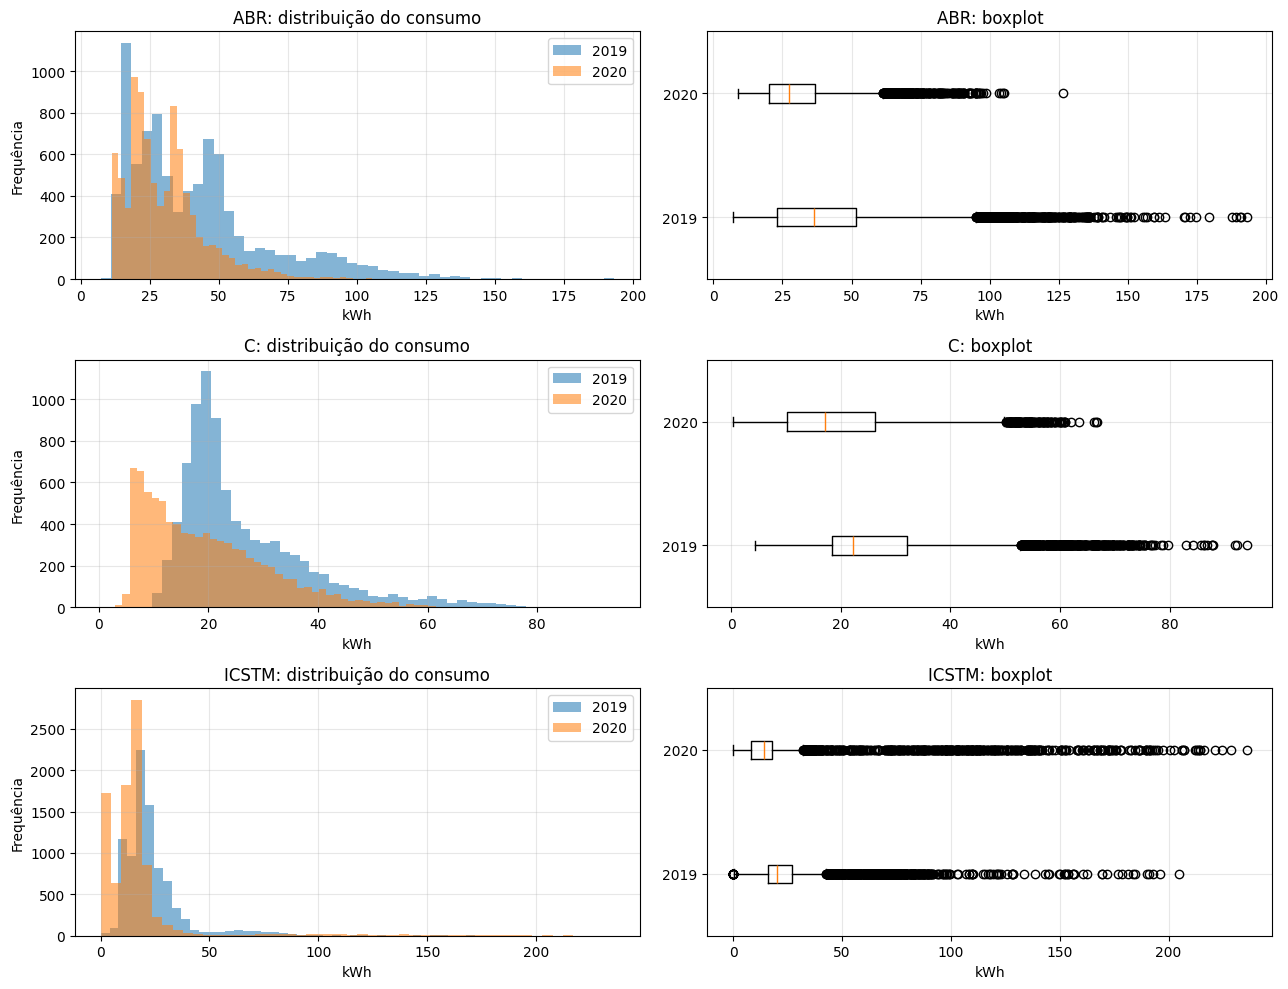

In [53]:
fig, ax = plt.subplots(3, 2, figsize=(13, 10))
for i, ed in enumerate(EDIFICIOS):
    g = d[d.edificio == ed]
    for a in anos:
        ax[i, 0].hist(g[g.ano == a]["consumo"], bins=50, alpha=0.55, label=str(a))
    ax[i, 0].set(title=f"{ed}: distribuição do consumo", xlabel="kWh", ylabel="Frequência"); ax[i, 0].legend()
    ax[i, 1].boxplot([g[g.ano == a]["consumo"] for a in anos], orientation="horizontal", tick_labels=[str(a) for a in anos])
    ax[i, 1].set(title=f"{ed}: boxplot", xlabel="kWh")
plt.tight_layout(); plt.show()

## Valores em falta ou inconsistentes
Valores em falta, valores inconsistentes (≤ 0), duplicados, regularidade da frequência e outliers (regra do IQR).

In [54]:
linhas = []
for (ed, a), g in d.groupby(["edificio", "ano"]):
    x = g["consumo"]
    q1, q3 = x.quantile([0.25, 0.75]); iqr = q3 - q1
    n_out = ((x > q3 + 1.5*iqr) | (x < q1 - 1.5*iqr)).sum()
    linhas.append({
        "edificio": ed, "ano": a,
        "em falta": int(x.isna().sum()),
        "<= 0": int((x <= 0).sum()),
        "duplicados": int(x.index.duplicated().sum()),
        "freq. 1h": bool((x.index.to_series().diff().dropna() == pd.Timedelta("1h")).all()),
        "outliers IQR": int(n_out),
        "% outliers": round(100 * n_out / len(x), 1),
    })
pd.DataFrame(linhas).set_index(["edificio", "ano"])

em falta  <= 0  duplicados  freq. 1h  outliers IQR  % outliers
edificio ano                                                                 
ABR      2019         0     0           0      True           477         5.4
         2020         0     0           0      True           326         3.7
C        2019         0     0           0      True           460         5.3
         2020         0     0           0      True           137         1.6
ICSTM    2019         0    17           0      True           643         7.3
         2020         0   652           0      True           546         6.2

In [55]:
# Onde estão os valores <= 0? (consumo nulo real ou falha de medição?)
z = d[d["consumo"] <= 0]
if len(z) == 0:
    print("Nenhum valor <= 0.")
for ed, g in z.groupby("edificio"):
    print(f"=== {ed}: {len(g)} horas com consumo <= 0")
    print(g.groupby(["ano", "mes"]).size().rename("horas").unstack(0).fillna(0).astype(int).T.to_string())
    grupo = (g.index.to_series().diff() != pd.Timedelta("1h")).cumsum()
    blocos = sorted(g.groupby(grupo.values).apply(lambda b: (b.index.min(), b.index.max(), len(b))), key=lambda t: -t[2])[:5]
    print("Maiores sequências contínuas:")
    for ini, fim, n in blocos:
        print(f"   {ini} -> {fim} ({n} h)")
    print()

=== ICSTM: 669 horas com consumo <= 0
mes   1   2   3    4    5   6   7   8   9   10  11
ano                                               
2019   0   2   0    0    3   5   4   3   0   0   0
2020  40  37  99  103  112  38  43  66  86  21   7
Maiores sequências contínuas:
   2020-08-31 00:00:00 -> 2020-09-02 15:00:00 (64 h)
   2020-08-12 02:00:00 -> 2020-08-12 11:00:00 (10 h)
   2020-03-19 09:00:00 -> 2020-03-19 16:00:00 (8 h)
   2020-03-22 09:00:00 -> 2020-03-22 16:00:00 (8 h)
   2020-03-23 09:00:00 -> 2020-03-23 16:00:00 (8 h)



**Notas para o relatório:**
- 2020 foi bissexto (8784 h) mas os ficheiros têm 8760 registos: falta 1 dia e, sem timestamps, não é possível saber qual. Ao assumir início a 1 de janeiro, a série de 2020 termina a 30 de dezembro.
- Os valores a zero devem ser analisados antes da modelação: podem ser falhas de medição (tratar como valores em falta) em vez de consumo real.

## Evolução do consumo ao longo do tempo

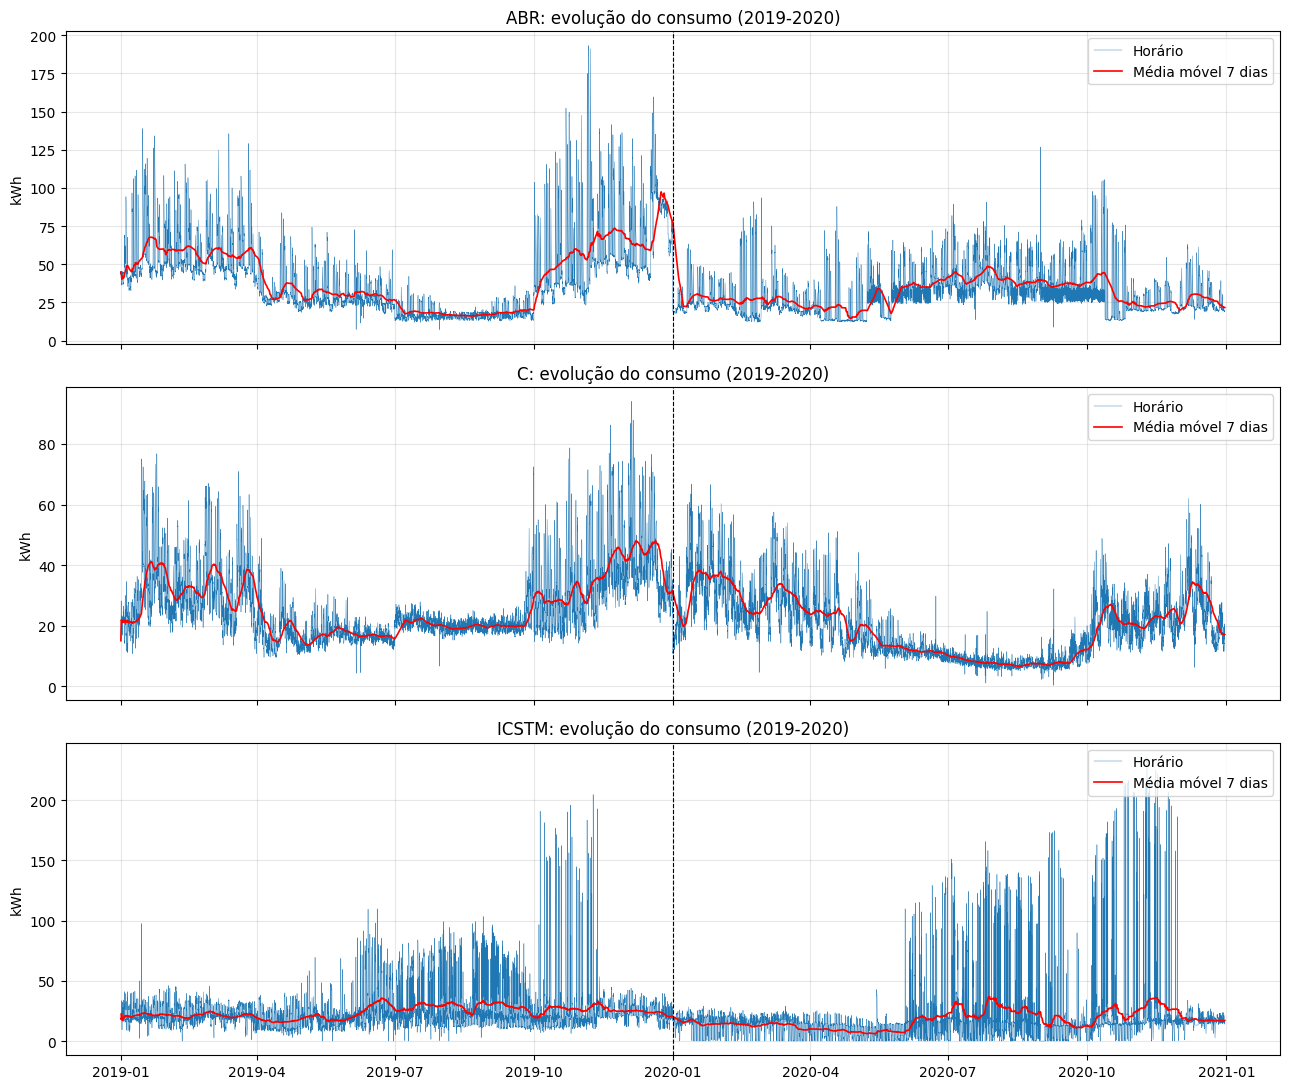

In [56]:
fig, ax = plt.subplots(3, 1, figsize=(13, 11), sharex=True)
for i, ed in enumerate(EDIFICIOS):
    s = d[d.edificio == ed]["consumo"]
    ax[i].plot(s, lw=0.3, label="Horário")
    ax[i].plot(s.rolling(24*7, min_periods=1).mean(), color="red", lw=1.2, label="Média móvel 7 dias")
    ax[i].axvline(pd.Timestamp("2020-01-01"), color="k", ls="--", lw=0.8)
    ax[i].set(title=f"{ed}: evolução do consumo (2019-2020)", ylabel="kWh"); ax[i].legend(loc="upper right")
plt.tight_layout(); plt.show()

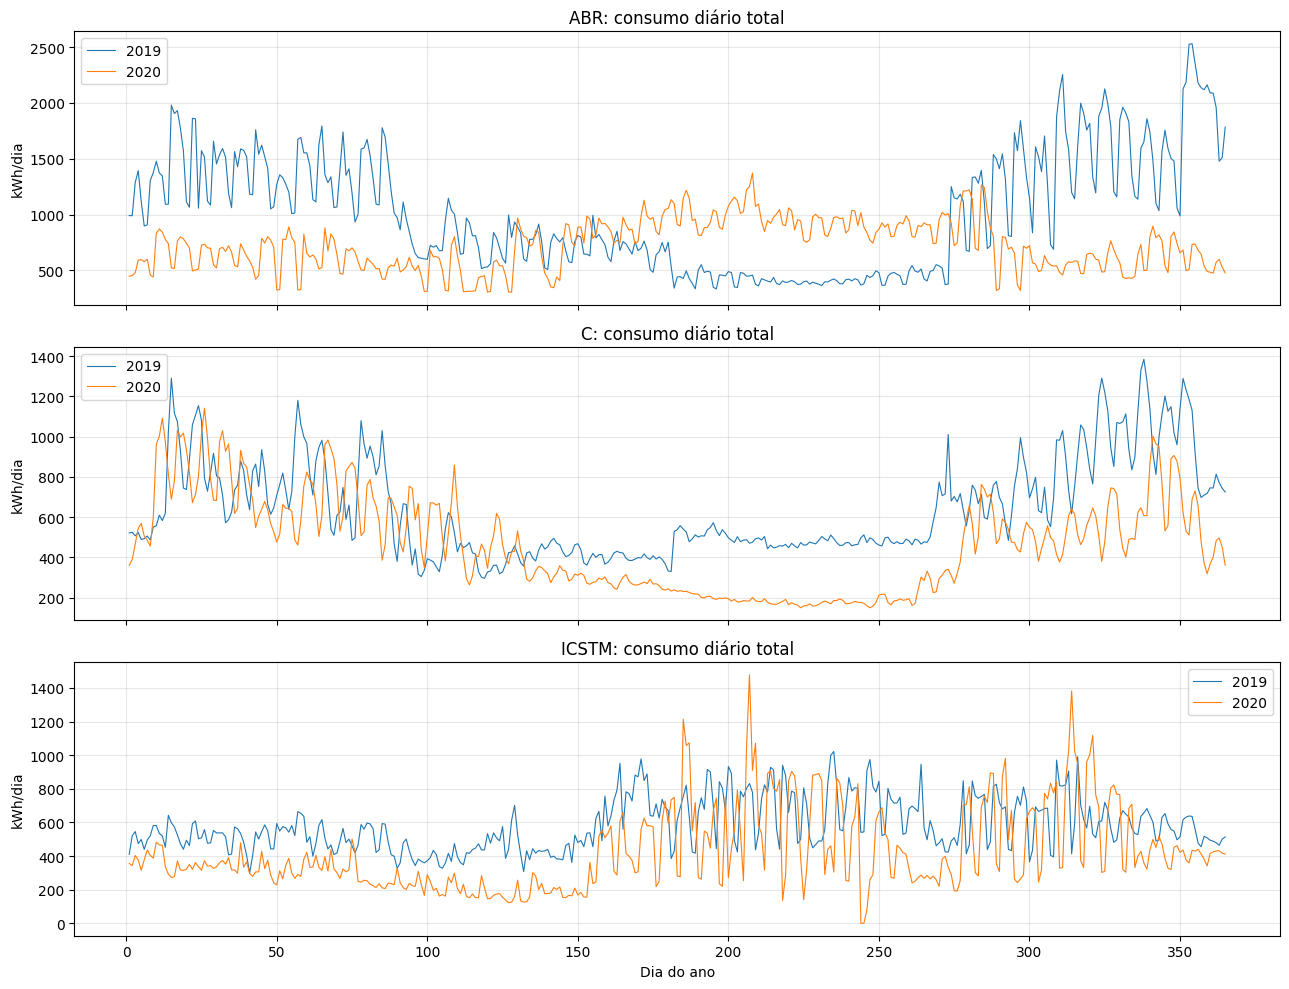

In [57]:
# 2019 vs 2020 sobrepostos (consumo diário total, por dia do ano)
fig, ax = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
for i, ed in enumerate(EDIFICIOS):
    for a in anos:
        x = d[(d.edificio == ed) & (d.ano == a)]["consumo"].resample("D").sum()
        ax[i].plot(x.index.dayofyear, x.values, lw=0.8, label=str(a))
    ax[i].set(title=f"{ed}: consumo diário total", ylabel="kWh/dia"); ax[i].legend()
ax[-1].set_xlabel("Dia do ano")
plt.tight_layout(); plt.show()

## Padrões diários, semanais e sazonais

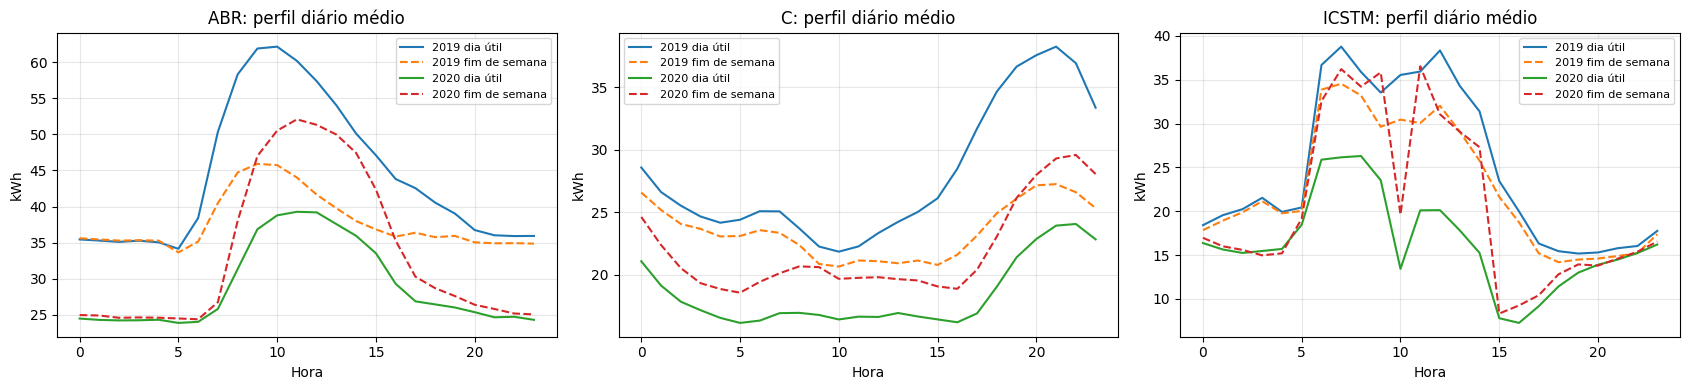

In [58]:
# Perfil diário médio: dia útil vs fim de semana
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for i, ed in enumerate(EDIFICIOS):
    for a in anos:
        p = d[(d.edificio == ed) & (d.ano == a)].groupby(["hora", "fim_semana"])["consumo"].mean().unstack()
        ax[i].plot(p.index, p[False], label=f"{a} dia útil")
        ax[i].plot(p.index, p[True], ls="--", label=f"{a} fim de semana")
    ax[i].set(title=f"{ed}: perfil diário médio", xlabel="Hora", ylabel="kWh"); ax[i].legend(fontsize=8)
plt.tight_layout(); plt.show()

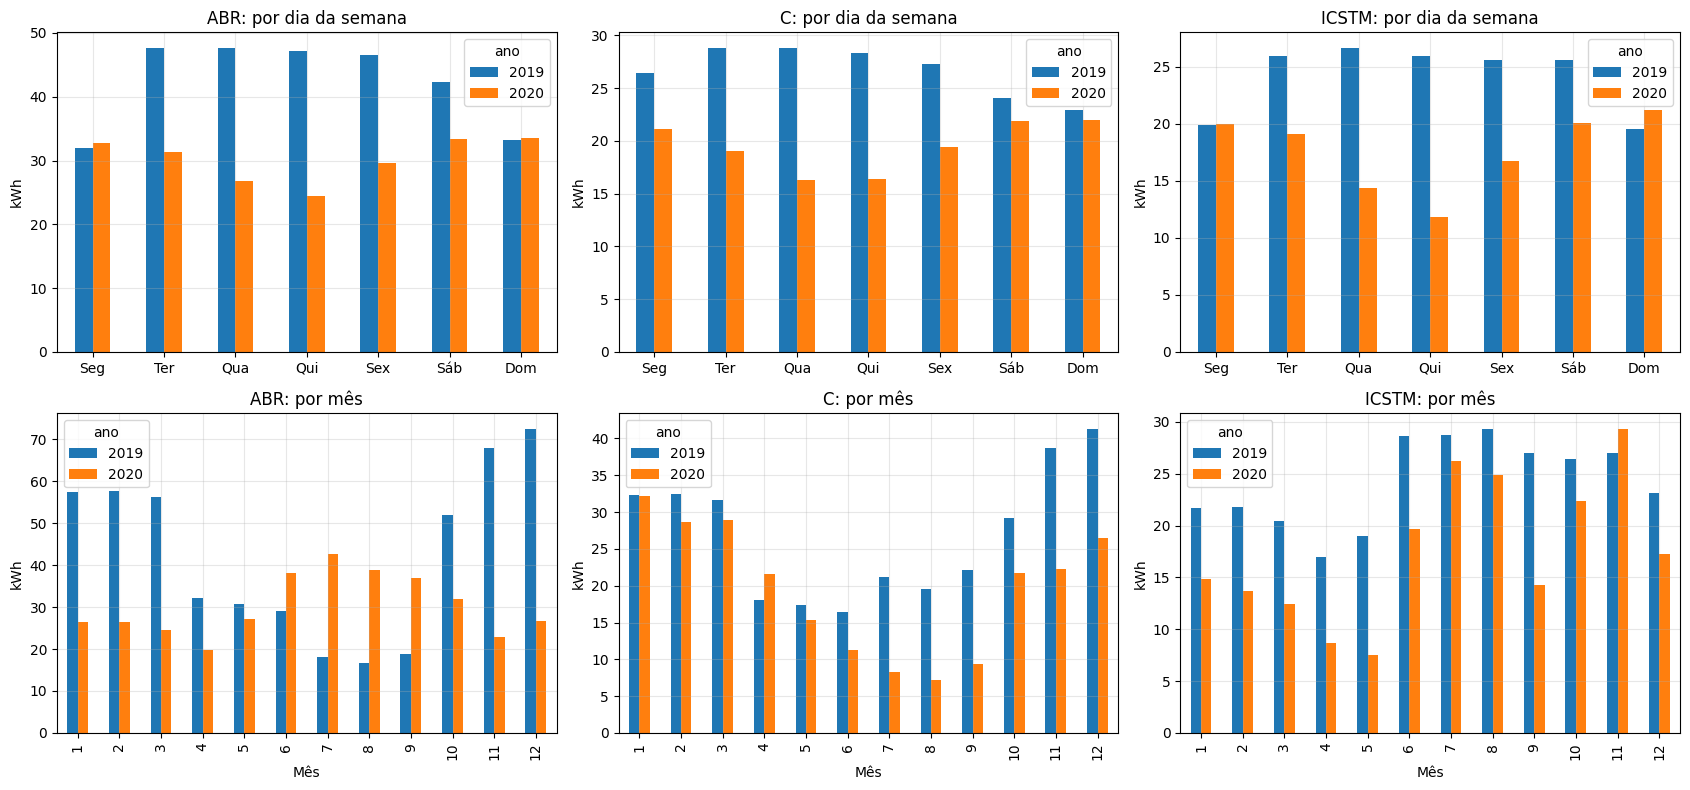

In [59]:
# Padrão semanal e sazonal (mensal)
fig, ax = plt.subplots(2, 3, figsize=(17, 8))
for i, ed in enumerate(EDIFICIOS):
    g = d[d.edificio == ed]
    g.groupby(["dia_semana", "ano"])["consumo"].mean().unstack().plot(kind="bar", ax=ax[0, i], title=f"{ed}: por dia da semana")
    ax[0, i].set_xticklabels(DIAS, rotation=0); ax[0, i].set(xlabel="", ylabel="kWh")
    g.groupby(["mes", "ano"])["consumo"].mean().unstack().plot(kind="bar", ax=ax[1, i], title=f"{ed}: por mês")
    ax[1, i].set(xlabel="Mês", ylabel="kWh")
plt.tight_layout(); plt.show()

**Observações a discutir (padrão semanal):**
- Em 2019, ABR e ICSTM têm segundas-feiras tão baixas como os domingos e sábados altos, ao contrário do esperado (fim de semana = sáb+dom). No C o padrão semanal é o esperado.
- Em 2020 o consumo ao fim de semana é igual ou superior ao de meio da semana nos três edifícios, e isto já acontece em janeiro e fevereiro (antes das restrições da pandemia), por isso não parece ser só um efeito do confinamento. Ver a verificação do calendário na secção 4.2.5.1.
- Como os ficheiros não têm datas, a ligação a datas reais é uma suposição. A secção 4.2.5.1 mostra que, em 5 das 6 séries, o padrão semanal só faz sentido com um deslocamento de dias, por isso estes padrões devem ser tratados como observações e não como conclusões.

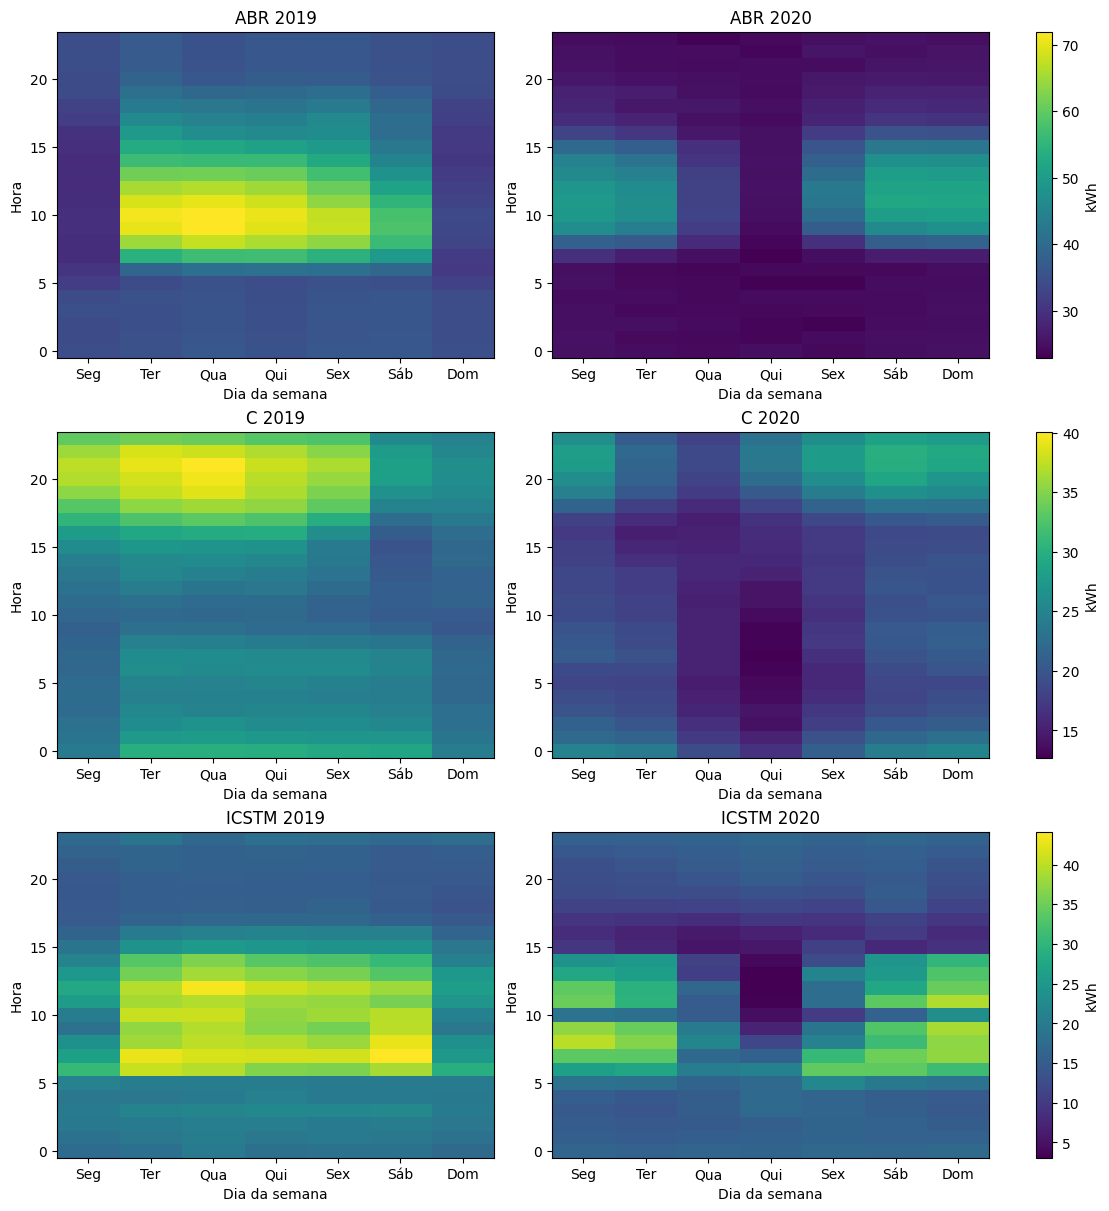

In [60]:
# Heatmaps hora x dia da semana (uma linha por edifício, uma coluna por ano)
fig, ax = plt.subplots(3, 2, figsize=(11, 12), constrained_layout=True)
for i, ed in enumerate(EDIFICIOS):
    pv = {a: d[(d.edificio == ed) & (d.ano == a)].pivot_table(index="hora", columns="dia_semana", values="consumo", aggfunc="mean") for a in anos}
    vmin = min(p.values.min() for p in pv.values()); vmax = max(p.values.max() for p in pv.values())
    for j, a in enumerate(anos):
        im = ax[i, j].imshow(pv[a], aspect="auto", cmap="viridis", origin="lower", vmin=vmin, vmax=vmax)
        ax[i, j].set(title=f"{ed} {a}", xlabel="Dia da semana", ylabel="Hora")
        ax[i, j].set_xticks(range(7)); ax[i, j].set_xticklabels(DIAS); ax[i, j].grid(False)
    fig.colorbar(im, ax=ax[i, :], label="kWh")
plt.show()

In [61]:
# Autocorrelação: confirma ciclos diários (24h) e semanais (168h)
rotulos = {
    1:   "hora anterior",
    2:   "2 h antes",
    3:   "3 h antes",
    12:  "12 h antes",
    24:  "mesma hora, dia anterior",
    48:  "mesma hora, 2 dias antes",
    168: "mesma hora, semana anterior",
}
ac = {(ed, a): {rot: round(d[(d.edificio == ed) & (d.ano == a)]["consumo"].autocorr(l), 3)
                for l, rot in rotulos.items()}
      for ed in EDIFICIOS for a in anos}
pd.DataFrame(ac).T

hora anterior  2 h antes  3 h antes  12 h antes  \
ABR   2019          0.974      0.921      0.857       0.487   
      2020          0.919      0.831      0.708       0.135   
C     2019          0.965      0.907      0.839       0.485   
      2020          0.965      0.928      0.888       0.753   
ICSTM 2019          0.662      0.465      0.317      -0.161   
      2020          0.498      0.368      0.165      -0.001   

            mesma hora, dia anterior  mesma hora, 2 dias antes  \
ABR   2019                     0.833                     0.687   
      2020                     0.767                     0.573   
C     2019                     0.874                     0.767   
      2020                     0.873                     0.758   
ICSTM 2019                     0.678                     0.522   
      2020                     0.653                     0.414   

            mesma hora, semana anterior  
ABR   2019                        0.858  
      2020                        0.753  
C     2019                        0.760  
      2020                        0.831  
ICSTM 2019                        0.679  
      2020                        0.600

## Períodos de consumo elevado ou reduzido

In [62]:
diario = d.groupby(["edificio", "ano"])["consumo"].resample("D").sum()
for ed in EDIFICIOS:
    for a in anos:
        dd = diario.loc[(ed, a)]
        g = d[(d.edificio == ed) & (d.ano == a)]
        mh = g.groupby("hora")["consumo"].mean(); mm = g.groupby("mes")["consumo"].mean()
        print(f"===== {ed} {a} =====")
        print("Dias de maior consumo :", ", ".join(f"{i.date()} ({v:.0f})" for i, v in dd.nlargest(5).items()))
        print("Dias de menor consumo :", ", ".join(f"{i.date()} ({v:.0f})" for i, v in dd.nsmallest(5).items()))
        print(f"Hora de pico médio: {mh.idxmax()}h | hora de mínimo médio: {mh.idxmin()}h")
        print(f"Mês de maior consumo: {mm.idxmax()} | mês de menor consumo: {mm.idxmin()}\n")

===== ABR 2019 =====
Dias de maior consumo : 2019-12-20 (2530), 2019-12-19 (2526), 2019-12-21 (2355), 2019-11-07 (2254), 2019-12-18 (2186)
Dias de menor consumo : 2019-07-15 (335), 2019-07-08 (336), 2019-07-01 (342), 2019-07-22 (348), 2019-07-14 (349)
Hora de pico médio: 10h | hora de mínimo médio: 5h
Mês de maior consumo: 12 | mês de menor consumo: 8

===== ABR 2020 =====
Dias de maior consumo : 2020-07-26 (1373), 2020-10-10 (1265), 2020-07-25 (1250), 2020-10-11 (1243), 2020-07-24 (1222)
Dias de menor consumo : 2020-05-07 (305), 2020-04-29 (306), 2020-05-06 (308), 2020-04-21 (309), 2020-04-08 (312)
Hora de pico médio: 11h | hora de mínimo médio: 5h
Mês de maior consumo: 7 | mês de menor consumo: 4

===== C 2019 =====
Dias de maior consumo : 2019-12-04 (1384), 2019-12-03 (1331), 2019-11-20 (1290), 2019-01-15 (1290), 2019-12-17 (1289)
Dias de menor consumo : 2019-04-29 (296), 2019-04-28 (301), 2019-04-08 (304), 2019-04-07 (316), 2019-05-04 (318)
Hora de pico médio: 21h | hora de mínimo 

In [63]:
# Variação 2020 vs 2019
m = d.groupby(["edificio", "ano"])["consumo"].mean().unstack()
m["variação %"] = (100 * (m[2020] / m[2019] - 1)).round(1)
m.round(2)

ano,2019,2020,variação %
edificio,,,
ABR,42.37,30.25,-28.6
C,26.67,19.42,-27.2
ICSTM,24.19,17.61,-27.2


## Comparação entre edifícios (complemento ao guião)
Perfil diário normalizado pela média do próprio edifício/ano (permite comparar a forma do consumo, independentemente da escala).

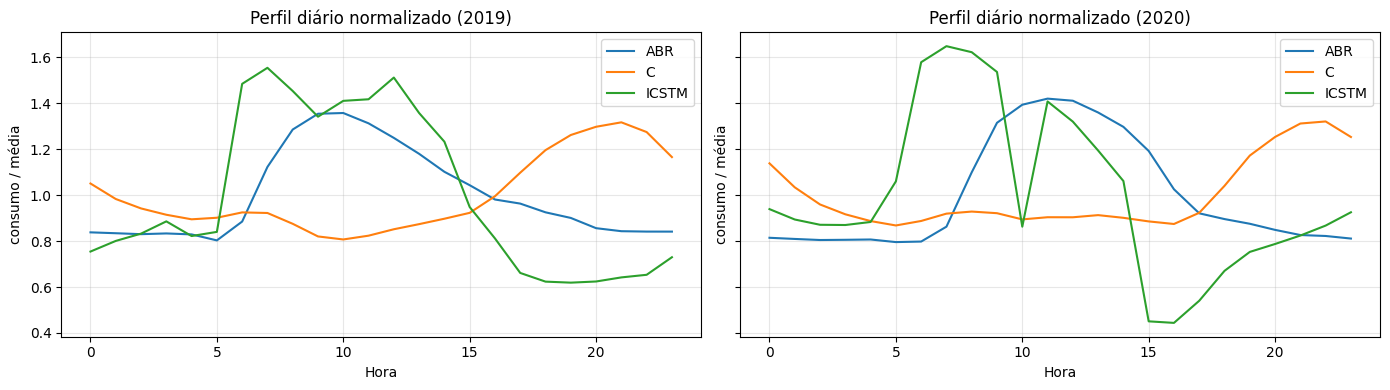

In [64]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for j, a in enumerate(anos):
    for ed in EDIFICIOS:
        g = d[(d.edificio == ed) & (d.ano == a)]
        p = g.groupby("hora")["consumo"].mean() / g["consumo"].mean()
        ax[j].plot(p.index, p.values, label=ed)
    ax[j].set(title=f"Perfil diário normalizado ({a})", xlabel="Hora", ylabel="consumo / média"); ax[j].legend()
plt.tight_layout(); plt.show()

## 4.1.9. Conclusões da análise exploratória
*(preencher com as observações do grupo, por edifício: padrão diário, dias úteis vs fim de semana, sazonalidade, diferenças entre 2019 e 2020, outliers, períodos anómalos, qualidade dos dados.)*

---
# 4.2. Preparação dos dados
Pontos do guião: verificação e ordenação temporal; tratamento de valores em falta ou inválidos; identificação de valores atípicos; verificação da periodicidade; criação de variáveis temporais (com justificação).
A tabela `dp` (*dados preparados*) parte da `d` usada na análise exploratória e acrescenta colunas; a `d` não é alterada.

## Verificação e ordenação temporal dos registos
Cada edifício passa a ter **uma série única, 2019 + 2020**, ordenada no tempo. Verifica-se que a ordem é crescente e que não há instantes repetidos.

In [65]:
dp = d.copy().sort_index(kind="stable")      # ordenação temporal (a ordem dentro de cada hora não importa)
linhas = []
for ed in EDIFICIOS:
    s = dp[dp.edificio == ed]["consumo"]
    linhas.append({"edifício": ed, "registos": len(s),
                   "ordem crescente": s.index.is_monotonic_increasing,
                   "sem datas repetidas": s.index.is_unique,
                   "início": s.index.min(), "fim": s.index.max()})
pd.DataFrame(linhas).set_index("edifício")

,registos,ordem crescente,sem datas repetidas,início,fim
edifício,,,,,
ABR,17520,True,True,2019-01-01,2020-12-30 23:00:00
C,17520,True,True,2019-01-01,2020-12-30 23:00:00
ICSTM,17520,True,True,2019-01-01,2020-12-30 23:00:00


## Tratamento de valores em falta ou inválidos
Não há valores em falta, mas há **zeros** no ICSTM (consumo ≤ 0), que num edifício em funcionamento são pouco plausíveis. Analisa-se o comprimento dos blocos de zeros consecutivos e define-se um tratamento.

**Proposta de tratamento**:
- blocos de zeros **curtos** (até `LIMITE_H` horas) são tratados como falhas de registo e substituídos por **interpolação linear**;
- blocos **longos** são mantidos como estão (podem ser paragens reais) e ficam assinalados na coluna `zero_longo`;
- o valor original fica guardado em `consumo_original`.

In [66]:
LIMITE_H = 3          # blocos de zeros com até 3 h consecutivas são interpolados

dp["consumo_original"] = dp["consumo"]
partes = []
for ed in EDIFICIOS:
    g = dp[dp.edificio == ed].copy()
    z = g["consumo_original"] <= 0
    bloco = (z != z.shift()).cumsum()                    # identifica cada sequência de zeros
    tamanho = z.groupby(bloco).transform("size")        # comprimento da sequência a que cada zero pertence
    g["zero_curto"] = z & (tamanho <= LIMITE_H)
    g["zero_longo"] = z & (tamanho > LIMITE_H)
    g["consumo"] = g["consumo_original"].mask(g["zero_curto"]).interpolate(method="time")
    partes.append(g)
dp = pd.concat(partes).sort_index(kind="stable")

resumo = dp.groupby(["edificio", "ano"]).agg(zeros_total=("consumo_original", lambda s: int((s <= 0).sum())),
                                              interpolados=("zero_curto", "sum"),
                                              mantidos=("zero_longo", "sum"))
resumo

zeros_total  interpolados  mantidos
edificio ano                                      
ABR      2019            0             0         0
         2020            0             0         0
C        2019            0             0         0
         2020            0             0         0
ICSTM    2019           17             9         8
         2020          652           239       413

In [67]:
# Efeito nas estatísticas do ICSTM (antes vs depois do tratamento)
g = dp[dp.edificio == "ICSTM"]
pd.DataFrame({"antes": g.groupby("ano")["consumo_original"].agg(["mean", "min"]).stack(),
              "depois": g.groupby("ano")["consumo"].agg(["mean", "min"]).stack()}).round(2).T

ano      2019        2020     
         mean  min   mean  min
antes   24.19  0.0  17.61  0.0
depois  24.20  0.0  17.74  0.0

## Identificação de valores atípicos
Usou-se o IQR sobre toda a série, que tende a marcar os picos normais do ciclo diário. Aqui compara-se cada valor com o **padrão típico da sua hora e do seu dia da semana** (mediana por edifício, ano, hora e dia da semana) e mede-se o desvio em unidades de MAD (desvio absoluto mediano, mais robusto que o desvio-padrão). Consideram-se atípicos os valores com |desvio| > `LIMIAR_MAD`.

Os valores atípicos são **apenas assinalados** (coluna `atipico`), não removidos: num problema de previsão fazem parte do comportamento real, e removê-los do conjunto de teste tornaria a avaliação demasiado otimista.

In [68]:
LIMIAR_MAD = 5
chave = [dp["edificio"], dp["ano"], dp["hora"], dp["dia_semana"]]
mediana = dp.groupby(chave)["consumo"].transform("median")
mad = (dp["consumo"] - mediana).abs().groupby(chave).transform("median") * 1.4826
dp["desvio_mad"] = (dp["consumo"] - mediana) / mad.replace(0, np.nan)
dp["atipico"] = dp["desvio_mad"].abs() > LIMIAR_MAD

t = dp.groupby(["edificio", "ano"])["atipico"].agg(["sum", "mean"])
t.columns = ["nº atípicos", "% atípicos"]; t["% atípicos"] = (100 * t["% atípicos"]).round(1)
t

nº atípicos  % atípicos
edificio ano                          
ABR      2019            0         0.0
         2020            2         0.0
C        2019           54         0.6
         2020            0         0.0
ICSTM    2019          248         2.8
         2020          516         5.9

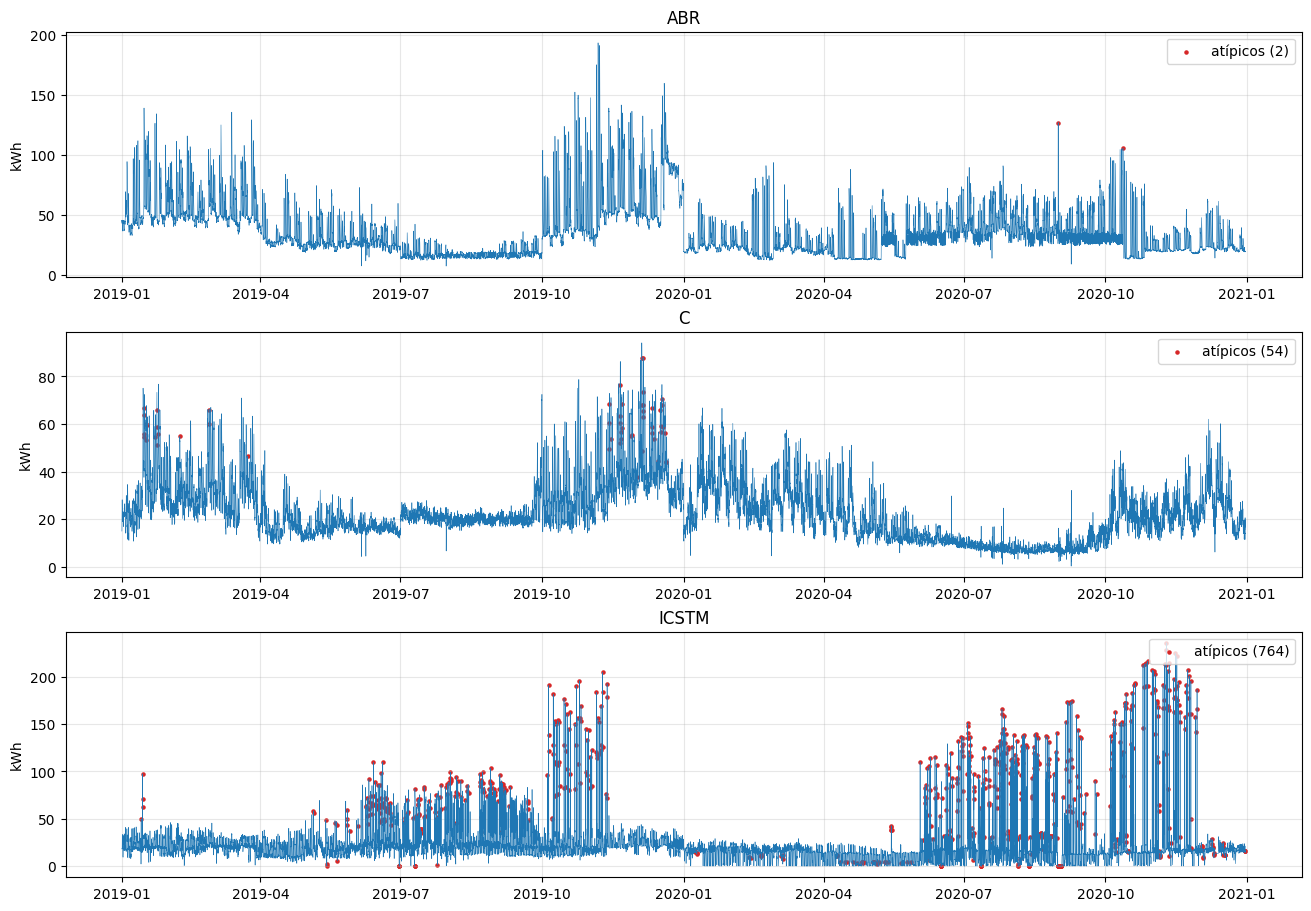

In [69]:
fig, ax = plt.subplots(3, 1, figsize=(13, 9), constrained_layout=True)
for i, ed in enumerate(EDIFICIOS):
    g = dp[dp.edificio == ed]
    ax[i].plot(g.index, g["consumo"], lw=0.4, color="tab:blue")
    at = g[g["atipico"]]
    ax[i].scatter(at.index, at["consumo"], s=5, color="tab:red", label=f"atípicos ({len(at)})")
    ax[i].set(title=ed, ylabel="kWh"); ax[i].legend(loc="upper right")
plt.show()

**Leitura:** o ABR e o C têm muito poucos atípicos. No **ICSTM** são muito mais frequentes (2,8 % em 2019 e 5,9 % em 2020), quase todos picos acima do esperado e concentrados entre maio e novembro. A mediana dos atípicos é cerca de 73 kWh/h (chega a 236), quando a mediana do edifício é cerca de 17 kWh/h. Alguns atípicos são os próprios zeros mantidos na secção 4.2.2. Não parecem erros isolados, mas períodos em que o edifício funciona de forma diferente, e por isso não se removem. É um edifício difícil de prever, e na análise de erros convém ver estes períodos em separado.

## Verificação da periodicidade dos registos
O intervalo entre registos consecutivos deve ser sempre 1 hora, inclusive na passagem de 2019 para 2020.

In [70]:
linhas = []
for ed in EDIFICIOS:
    s = dp[dp.edificio == ed]["consumo"]
    dif = s.index.to_series().diff().dropna()
    linhas.append({"edifício": ed,
                   "intervalos distintos": dif.nunique(),
                   "intervalo": str(dif.iloc[0]),
                   "dias em 2019": s[s.index.year == 2019].index.normalize().nunique(),
                   "dias em 2020": s[s.index.year == 2020].index.normalize().nunique()})
pd.DataFrame(linhas).set_index("edifício")

,intervalos distintos,intervalo,dias em 2019,dias em 2020
edifício,,,,
ABR,1,0 days 01:00:00,365,365
C,1,0 days 01:00:00,365,365
ICSTM,1,0 days 01:00:00,365,365


- A periodicidade é de **1 hora** em todos os edifícios, sem falhas.
- **2020 tem 365 dias em vez de 366** (ano bissexto), ou seja, faltam 24 h. Assumiu-se que a série termina a 30 de dezembro. Se o dia em falta estivesse noutro ponto, as datas seguintes estariam deslocadas um dia (ver secção 4.2.5.1).
- Os ficheiros não indicam fuso horário e não mostram dias de 23 h ou 25 h, por isso não há ajuste de hora de verão/inverno.

## Criação de variáveis temporais
Inclui a verificação do calendário (que condiciona as variáveis de dia da semana e dia útil), a criação das variáveis e a sua justificação em função do problema de previsão.

### 1. Verificação prévia do calendário (dia da semana)
Os ficheiros não têm datas, e as variáveis `dia_semana`, `fim_semana` e dia útil dependem de a série começar mesmo a 1 de janeiro. Para testar isso, usa-se um padrão semanal esperado (dias úteis com mais consumo, fim de semana com menos) e mede-se a correlação com o perfil semanal observado em cada série. Depois testa-se também o perfil rodado de 1 a 6 dias, e guarda-se o deslocamento com melhor correlação.

Se o calendário assumido estiver certo, o deslocamento melhor é **0**.

In [71]:
molde = np.array([1, 1, 1, 1, 1, 0, 0], float)     # Seg..Sex altos, Sáb e Dom baixos
linhas, perfis = [], {}
for ed in EDIFICIOS:
    for a in anos:
        dia = dp[(dp.edificio == ed) & (dp.ano == a)]["consumo"].resample("D").mean()
        p = dia.groupby(dia.index.dayofweek).mean().values
        perfis[(ed, a)] = p / p.mean()
        corrs = [np.corrcoef(np.roll(p, k), molde)[0, 1] for k in range(7)]   # k = dias a somar ao calendário assumido
        k = int(np.argmax(corrs))
        linhas.append({"edifício": ed, "ano": a,
                       "corr. (calendário assumido)": round(corrs[0], 2),
                       "melhor deslocamento (dias)": k,
                       "corr. (com deslocamento)": round(corrs[k], 2)})
pd.DataFrame(linhas).set_index(["edifício", "ano"])

corr. (calendário assumido)  melhor deslocamento (dias)  \
edifício ano                                                             
ABR      2019                         0.45                           6   
         2020                        -0.62                           3   
C        2019                         0.92                           0   
         2020                        -0.71                           3   
ICSTM    2019                         0.35                           6   
         2020                        -0.60                           3   

               corr. (com deslocamento)  
edifício ano                             
ABR      2019                      0.96  
         2020                      0.91  
C        2019                      0.92  
         2020                      0.89  
ICSTM    2019                      0.99  
         2020                      0.89

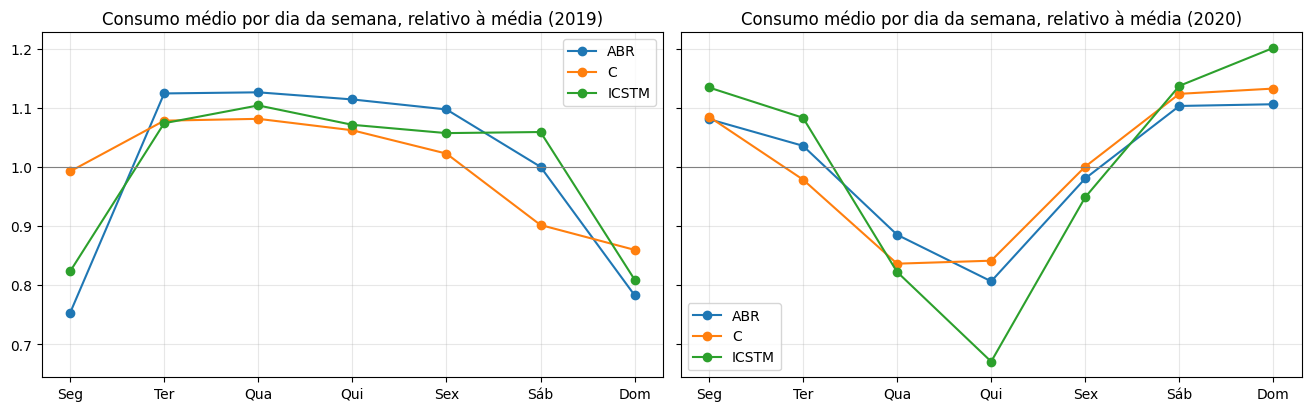

In [72]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True, constrained_layout=True)
for j, a in enumerate(anos):
    for ed in EDIFICIOS:
        ax[j].plot(DIAS, perfis[(ed, a)], marker="o", label=ed)
    ax[j].axhline(1, color="gray", lw=0.8); ax[j].set(title=f"Consumo médio por dia da semana, relativo à média ({a})"); ax[j].legend()
plt.show()

**Leitura:** só o edifício C em 2019 tem o padrão semanal esperado com o calendário assumido. Nas restantes séries o fim de semana só aparece como dias de menor consumo se os dias forem deslocados (por exemplo, em 2020 todos os edifícios encaixam com 3 dias de deslocamento, e em 2019 o ABR e o ICSTM com 6).

Em 2020 o padrão (consumo mais baixo à quarta e quinta-feira) já existe em janeiro e fevereiro, antes das restrições da pandemia, por isso não parece ser só um efeito do confinamento. Por outro lado, há sinais a favor do alinhamento por 1 de janeiro (consumo mínimo a 1–2 de janeiro no ABR, quebra na Páscoa ortodoxa de 2019). As evidências não são coerentes entre si e **não é possível resolver isto só com os ficheiros**. Possíveis causas: início das séries noutro dia, ou dias em falta ou repetidos.

**Consequência:** o dia da semana, o fim de semana e o dia útil **não estão confirmados** com as datas assumidas, e os feriados nacionais também não podem ser usados sem datas certas. Enquanto isto não for esclarecido (por exemplo, verificando a origem dos dados no Zenodo ou com os autores), o conjunto base de variáveis usa só a **hora do dia** e os **consumos anteriores** (t-1, t-24 e t-168), que já capturam os ciclos diário e semanal sem precisar do calendário. As variáveis de calendário ficam disponíveis como opcionais.

### 2. Variáveis criadas
Cada linha representa **a hora a prever**; as variáveis só usam informação **anterior** a essa hora (sem informação futura).

- **Hora do dia:** codificada em seno/cosseno, para a hora 23 ficar perto da hora 0.
- **Consumo em horas anteriores:** `consumo_hora_anterior` (hora anterior), `consumo_dia_anterior` (mesma hora do dia anterior) e `consumo_semana_anterior` (mesma hora da semana anterior), calculados dentro de cada edifício com o consumo já tratado.

In [75]:
# Hora do dia em seno/cosseno
dp["hora_seno"] = np.sin(2 * np.pi * dp["hora"] / 24);       dp["hora_cosseno"] = np.cos(2 * np.pi * dp["hora"] / 24)

# Consumos anteriores (dentro de cada edifício; a série é contínua, com 1 h entre registos)
for k, nome in {1: "consumo_hora_anterior", 24: "consumo_dia_anterior", 168: "consumo_semana_anterior"}.items():
    dp[nome] = dp.groupby("edificio")["consumo"].shift(k)

FEATURES_BASE = ["hora_seno", "hora_cosseno", "consumo_hora_anterior", "consumo_dia_anterior", "consumo_semana_anterior"]

print("Linhas sem consumo anterior (início da série de cada edifício):", dp["consumo_semana_anterior"].isna().sum() // len(EDIFICIOS), "por edifício")
dp[dp.edificio == "ABR"][["consumo"] + FEATURES_BASE].iloc[[0, 1, 168, 169, 170]].round(3)

Linhas sem consumo anterior (início da série de cada edifício): 168 por edifício


,consumo,hora_seno,hora_cosseno,consumo_hora_anterior,consumo_dia_anterior,consumo_semana_anterior
2019-01-01 00:00:00,44.630,0.000,1.000,NaN,NaN,NaN
2019-01-01 01:00:00,45.302,0.259,0.966,44.630,NaN,NaN
2019-01-08 00:00:00,40.403,0.000,1.000,40.305,41.686,44.630
2019-01-08 01:00:00,40.830,0.259,0.966,40.403,41.124,45.302
2019-01-08 02:00:00,39.816,0.500,0.866,40.830,40.378,43.848


### Justificação das variáveis em função do problema
O objetivo é prever o consumo da hora seguinte, e a análise exploratória mostrou o que ajuda:

| Variável | Justificação |
|---|---|
| `consumo_hora_anterior` (hora anterior) | O consumo varia pouco de uma hora para a seguinte: autocorrelação de 0,92 a 0,97 no ABR e no C. No ICSTM é menor (0,50 a 0,66), com mais saltos. |
| `consumo_dia_anterior` (mesma hora do dia anterior) | Ciclo diário forte: autocorrelação de 0,65 a 0,87 em todas as séries. |
| `consumo_semana_anterior` (mesma hora da semana anterior) | Ciclo semanal: autocorrelação de 0,60 a 0,86. Capta o efeito dia útil/fim de semana sem precisar do calendário. |
| `hora_seno`, `hora_cosseno` | O perfil ao longo do dia é muito marcado e muda por edifício (picos por volta das 10h–11h no ABR, 21h–22h no C e 7h no ICSTM). |

In [ ]:
# Correlação de Pearson entre o consumo e cada variável candidata (só relação linear)
cand = ["consumo_hora_anterior", "consumo_dia_anterior", "consumo_semana_anterior", "hora_seno", "hora_cosseno"]
x = dp.dropna(subset=["consumo_semana_anterior"])
pd.DataFrame({ed: x[x.edificio == ed][["consumo"] + cand].astype(float).corr()["consumo"].drop("consumo") for ed in EDIFICIOS}).round(2)

,ABR,C,ICSTM
consumo_hora_anterior,0.96,0.97,0.56
consumo_dia_anterior,0.83,0.88,0.67
consumo_semana_anterior,0.82,0.81,0.63
hora_seno,0.03,-0.18,0.21
hora_cosseno,-0.30,0.18,-0.18
dia_semana_seno,0.03,0.00,-0.01
dia_semana_cosseno,-0.05,0.02,0.01
mes_seno,-0.11,-0.07,-0.17
mes_cosseno,0.28,0.62,-0.09
dia_util,0.02,0.02,-0.02


*Nota: a correlação de Pearson só mede relação linear. `hora_sin` e `hora_cos` podem dar valores baixos mesmo sendo úteis, porque o perfil diário não é uma sinusoide (por exemplo, o pico estreito do ICSTM).*

## Resumo da preparação dos dados
- **Ordenação e periodicidade:** séries ordenadas e com 1 h entre registos, 2019 + 2020 (2020 com 365 dias, falta 1 dia).
- **Valores em falta:** não existem. 
- **Zeros do ICSTM:** blocos até 3 h interpolados; blocos mais longos mantidos e assinalados (`zero_longo`).
- **Atípicos:** assinalados (`atipico`), não removidos.
- **Calendário:** dia da semana, fim de semana e feriados **não confirmados** com as datas assumidas (secção 4.2.5.1). A confirmar antes de usar.
- **Variáveis base:** `hora_sin`, `hora_cos`, `lag_1`, `lag_24`, `lag_168`. Opcionais: dia da semana, mês, dia útil.
- **Próximo passo (4.3):** divisão cronológica treino/validação/teste, escalonamento ajustado só no treino e remoção das primeiras 168 h sem `lag_168`.

*(Para partilhar com o grupo, a tabela `dp` pode ser guardada com `dp.to_csv("dados_preparados.csv")`.)*